# Block 6: Implied vs. Realized Volatility — Does the VIX Forecast Volatility?

**Objective.** Test whether the VIX, the volatility implied by S&P 500 option prices over the next 30
calendar days, correctly forecasts the volatility that is actually realized over the next 21 trading days.

**Data.** The VIX comes from FRED (VIXCLS), the reference source after a three-way check against
Yahoo Finance and Cboe showed an incorrect Yahoo close on 2026-02-06. Realized volatility is computed
from S&P 500 daily log returns over days t+1 to t+21, so the last 21 dates are dropped (their future is
not yet known). The VIX closes at 4:15 pm and the S&P 500 at 4:00 pm; since realized volatility starts
on the next day, this 15-minute gap does not bias the comparison.

**Benchmark.** A naive forecast: next month's volatility equals the volatility realized over the
previous 21 trading days.

In [2]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from volrisk.config import FIGURES
from volrisk.data import load_raw, load_fred_vix
from volrisk.returns import log_returns
from volrisk.vix import (build_forecast_table, forecast_errors,
                         mincer_zarnowitz, variance_risk_premium)

In [3]:
r = log_returns(load_raw("sp500")["Close"])
table = build_forecast_table(load_fred_vix(), r, horizon=21)
table.describe().loc[["count", "mean", "50%", "min", "max"]].style.format("{:.2%}", subset=pd.IndexSlice[["mean", "50%", "min", "max"], :])

Raw data for 'sp500' loaded from 'C:\dev\volatility-analysis\data\raw\sp500.csv'.
33 VIX dates without an S&P 500 return were dropped: 2022-05-30, 2022-06-20, 2022-07-04, 2022-09-05, 2022-11-24, 2023-01-16, 2023-02-20, 2023-05-29, 2023-06-19, 2023-07-04, 2023-09-04, 2023-11-23, 2024-01-15, 2024-02-19, 2024-05-27, 2024-06-19, 2024-07-04, 2024-09-02, 2024-11-28, 2025-01-09, 2025-01-20, 2025-02-17, 2025-05-26, 2025-06-19, 2025-07-04, 2025-09-01, 2025-11-27, 2026-01-19, 2026-02-16, 2026-05-25, 2026-06-19, 2026-07-03, 2026-09-07.


,vix,naive,realized_vol
count,2933.000000,2933.000000,2933.000000
mean,18.32%,14.84%,14.81%
50%,16.59%,12.43%,12.35%
min,9.14%,3.47%,3.47%
max,82.69%,97.56%,97.56%


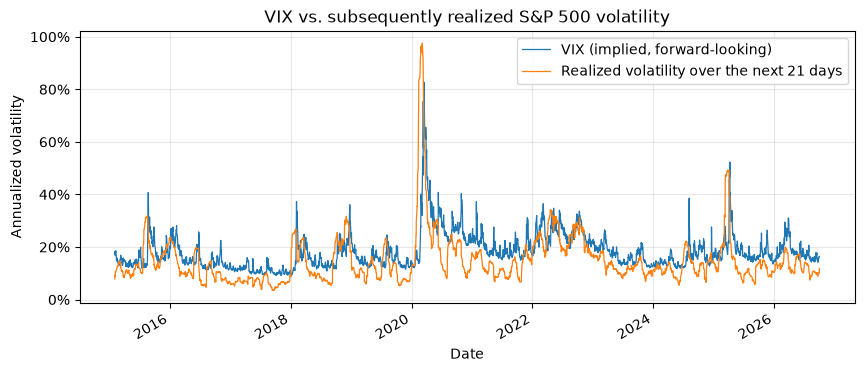

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
table["vix"].plot(ax=ax, linewidth=0.9, label="VIX (implied, forward-looking)")
table["realized_vol"].plot(ax=ax, linewidth=0.9, label="Realized volatility over the next 21 days")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_title("VIX vs. subsequently realized S&P 500 volatility")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized volatility")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(FIGURES / "06_vix_vs_realized.png", dpi=150, bbox_inches="tight")
plt.show()

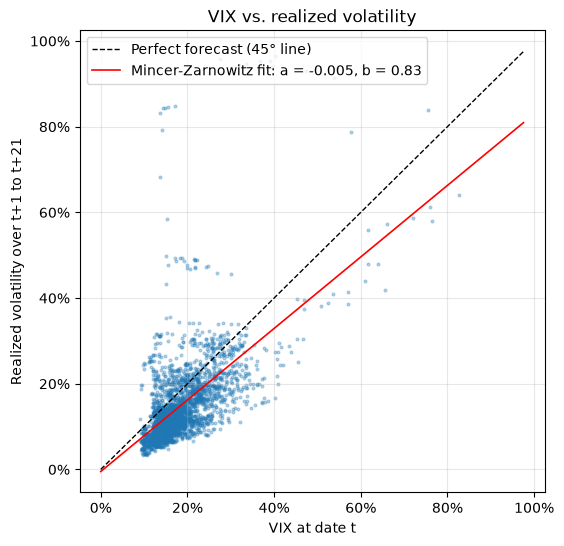

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(table["vix"], table["realized_vol"], s=4, alpha=0.3)
lim = [0, max(table["vix"].max(), table["realized_vol"].max())]
ax.plot(lim, lim, color="black", linestyle="--", linewidth=1, label="Perfect forecast (45° line)")

mz = mincer_zarnowitz(table, "vix")
x = np.linspace(*lim, 100)
ax.plot(x, mz["a"] + mz["b"] * x, color="red", linewidth=1.2,
        label=f"Mincer-Zarnowitz fit: a = {mz['a']:.3f}, b = {mz['b']:.2f}")

ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_xlabel("VIX at date t")
ax.set_ylabel("Realized volatility over t+1 to t+21")
ax.set_title("VIX vs. realized volatility")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
fig.savefig(FIGURES / "06_vix_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the scatter plot.** Each point is one date: the VIX on the x-axis, the volatility realized
over the following month on the y-axis. A perfect forecast would put every point on the dashed 45° line.
- Most points lie *below* the 45° line: realized volatility is usually lower than the VIX.
- The red Mincer-Zarnowitz line (`realized = a + b × VIX`) is flatter than the 45° line (b = 0.83), so
  the gap between forecast and outcome widens as the VIX rises.
- The vertical clusters of points with a VIX of 13–20% but a realized volatility of 45–85% are the dates
  just before the COVID crash (February 2020) and the April 2025 sell-off: shocks that were not priced in.
  They drive the largest forecast errors, for any model.

In [6]:
display(forecast_errors(table).style.format("{:.2%}"))

mz_table = pd.concat([mincer_zarnowitz(table, "vix"), mincer_zarnowitz(table, "naive")], axis=1)
mz_table.style.format("{:.4f}")

,vix,naive
bias,3.51%,0.03%
mae,6.18%,5.72%
rmse,8.75%,9.95%


,vix,naive
a,-0.0048,0.0756
b,0.8346,0.4885
se_a,0.0177,0.0118
se_b,0.1110,0.0930
r_squared,0.3503,0.2383
p_value_a0_b1,0.0000,0.0000
n_obs,2933.0000,2933.0000


**Forecast errors.** The VIX overestimates realized volatility by 3.5 points on average, whereas the
naive forecast is almost unbiased (+0.03 point): over a long sample, the mean of past volatility equals
the mean of future volatility. The two error measures then rank the forecasts differently:
- MAE (mean absolute error): naive 5.72% < VIX 6.18%. On a typical day, the VIX's systematic upward
  bias costs it more than it gains.
- RMSE (root mean squared error, which penalizes large errors more heavily): VIX 8.75% < naive 9.95%.
  When volatility changes sharply, the VIX adapts faster, while the naive forecast is stuck on the past month.

**Mincer-Zarnowitz regression** (Mincer & Zarnowitz, 1969): `realized_vol = a + b × forecast + error`.
An unbiased, efficient forecast has a = 0 and b = 1. Standard errors are Newey-West HAC with 21 lags
(Newey & West, 1987), because consecutive 21-day windows overlap and the residuals are autocorrelated.
- **VIX:** b = 0.83 (standard error 0.11), R² = 0.35. Taken individually, neither a = 0 nor b = 1 is
  rejected at 5% (t-stat for b = 1: `(0.83 − 1) / 0.11 ≈ −1.5`). Yet the joint Wald test rejects strongly
  (p < 0.0001): the estimates of a and b are strongly negatively correlated, and the joint test detects
  what the individual t-stats miss, namely that the fitted line lies about 3.5 points below the 45° line
  around the average VIX. The VIX's weakness is its **level** (an upward bias), not its information content.
- **Naive forecast:** b = 0.49 (standard error 0.09), clearly below 1, with a = 0.08. A volatility that was
  high last month tends to fall back, and a low one tends to rise: volatility is **mean-reverting**, so
  past volatility over-reacts and has to be shrunk toward its long-run average.
- The VIX explains more of future volatility than the past does (R² 0.35 vs. 0.24): option prices contain
  information that past returns do not.

In [7]:
# Robustness: one observation per month (last trading day), so 21-day windows barely overlap
monthly = table.resample("ME").last().dropna()
mz_monthly = pd.concat([mincer_zarnowitz(monthly, "vix", hac_lags=1),
                        mincer_zarnowitz(monthly, "naive", hac_lags=1)], axis=1)
print(f"Monthly observations: {len(monthly)}")
mz_monthly.style.format("{:.4f}")

Monthly observations: 141


,vix,naive
a,-0.0241,0.0800
b,0.9374,0.4586
se_a,0.0358,0.0108
se_b,0.2223,0.0750
r_squared,0.3817,0.2044
p_value_a0_b1,0.0000,0.0000
n_obs,141.0000,141.0000


**Robustness: monthly, non-overlapping sample.** Two consecutive daily observations share 20 of their
21 future days, so the 2,933 points carry far less independent information than their number suggests.
Keeping only the last trading day of each month gives 141 nearly independent observations (HAC with 1 lag).
- VIX: b = 0.94 (standard error 0.22), R² = 0.38. The slope is even closer to 1, and the joint test
  still rejects because of the level bias.
- Naive: b = 0.46 (standard error 0.08), R² = 0.20.

The conclusions do not depend on the overlap: the VIX is upward-biased but more informative than past
volatility, which mean-reverts. Standard errors are larger, as expected with far fewer observations.

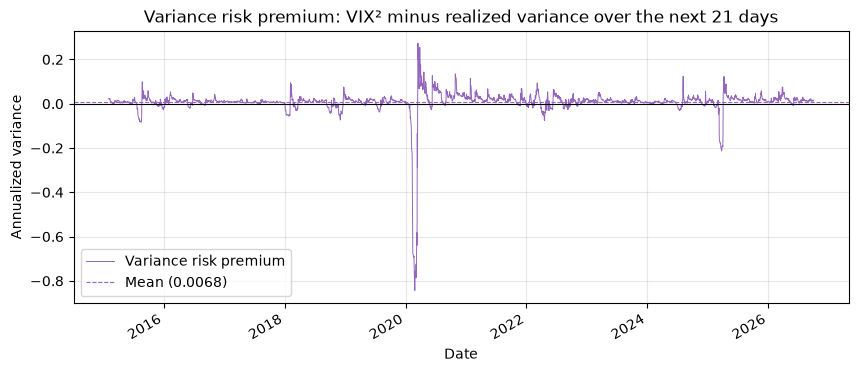

Share of days with VIX above realized volatility: 82.9%


In [8]:
vrp = variance_risk_premium(table)

fig, ax = plt.subplots(figsize=(10, 4))
vrp.plot(ax=ax, linewidth=0.7, color="tab:purple", label="Variance risk premium")
ax.axhline(0, color="black", linewidth=0.8)
ax.axhline(vrp.mean(), color="tab:purple", linestyle="--", linewidth=0.8, label=f"Mean ({vrp.mean():.4f})")
ax.set_title("Variance risk premium: VIX² minus realized variance over the next 21 days")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized variance")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(FIGURES / "06_variance_risk_premium.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Share of days with VIX above realized volatility: {(table['vix'] > table['realized_vol']).mean():.1%}")

## Block 6 — Key takeaways

1. The VIX is an **upward-biased** forecast of S&P 500 volatility: 18.3% on average vs. 14.8% realized,
   and above realized volatility on 83% of days.
2. This bias is not a mistake but a **price**: the variance risk premium investors pay for protection
   against crashes.
3. Beyond this level bias, the VIX is **more informative** than past volatility (R² 0.35 vs. 0.24 on daily
   data, 0.38 vs. 0.20 on monthly data), with a slope close to 1 (0.83 daily, 0.94 monthly).
4. The naive forecast is unbiased on average but over-reacts (b ≈ 0.5), because volatility **mean-reverts**.
5. Neither forecast anticipates sudden shocks (February 2020, April 2025): the largest errors come from
   events that were not priced in.
6. The results hold on a monthly non-overlapping sample, and all inference uses Newey-West standard errors.

**Possible extensions:** an encompassing regression combining the VIX and past volatility, a HAR model of
realized volatility (Corsi, 2009), a GARCH(1,1) forecast as an extra benchmark.

**Variance risk premium.** `VRP_t = VIX_t² − RV(t+1 → t+21)²` is the gap between the variance priced by
options and the variance actually realized (Carr & Wu, 2009; Bollerslev, Tauchen & Zhou, 2009). It is the
payoff of a variance seller: someone who sells volatility insurance at the VIX and pays out realized variance.
- The VIX is above realized volatility on 82.9% of days, and the mean premium is positive
  (0.0068 in annualized variance).
- The payoff is asymmetric: small gains most of the time, rare and very large losses (about −0.8 in
  February–March 2020, about −0.2 in early 2025, smaller ones in August 2015 and February 2018).
  This is the profile of an insurer, with the same negative skewness as the returns themselves (Block 3).
- Right after each crash the premium turns strongly positive: the VIX stays high while markets calm
  down, so insurance is most expensive just after it was needed.

**Methodological note.** The VIX is the square root of a risk-neutral expected variance over 30 calendar
days. By Jensen's inequality, `√E[σ²] ≥ E[σ]`, so part of the gap between the VIX and realized
*volatility* is mechanical rather than a risk premium. Comparing *variances* (VIX² vs. RV²), as done here,
avoids this issue. The 30 calendar days of the VIX match roughly, not exactly, 21 trading days.

# Project conclusion

Over 2015–2026, the S&P 500 grew at 11.7% a year with an annualized volatility of 17.7%, but this average
hides a very uneven risk profile. The six blocks tell one consistent story:

- **Returns (Block 1).** Daily returns are negatively skewed and fat-tailed (excess kurtosis ≈ 16), the
  stylized facts described by Cont (2001). Volatility drag lowers compounded growth by about `σ²/2` = 1.6
  points a year.
- **Volatility (Block 2).** Volatility is low most of the time (median 21-day volatility 12.4%) and spikes
  briefly (98% in March 2020). It rises when prices fall (leverage effect) and reverts to its mean.
- **Distribution (Block 3).** Returns are not normal, and their absolute values are strongly
  autocorrelated (volatility clustering, long memory). Scaling by past volatility removes about two thirds
  of the excess kurtosis but makes skewness more negative: crashes arrive when volatility is low.
- **Drawdowns (Block 4).** The maximum drawdown is −33.9% (COVID), recovered in 126 trading days. The
  2022 bear market was shallower (−25.4%) but took 513 trading days to recover: depth and duration are
  two different risks.
- **VaR and Expected Shortfall (Block 5).** A normal model underestimates 99% risk (VaR by 21%, ES by 37%).
  Even historical VaR fails the Kupiec test at 99%, because a one-year window adapts too slowly to
  volatility clusters.
- **VIX (Block 6).** Implied volatility overestimates realized volatility on average (variance risk
  premium) but forecasts it better than past volatility; neither anticipates sudden shocks.

**Common thread: risk is not constant.** Any tool that assumes constant volatility or normal returns
(normal VaR, √h scaling, unconditional forecasts) fails precisely in the periods that matter most. The
natural next step is a conditional volatility model (GARCH, Bollerslev, 1986) feeding a filtered VaR,
backtested with Christoffersen's (1998) independence test.

In [9]:
extra = load_fred_vix().index.difference(r.index)
extra = extra[(extra >= table.index[0]) & (extra <= table.index[-1])]
print(pd.Series(extra.day_name(), index=extra.date).to_string())

2022-05-30       Monday
2022-06-20       Monday
2022-07-04       Monday
2022-09-05       Monday
2022-11-24     Thursday
2023-01-16       Monday
2023-02-20       Monday
2023-05-29       Monday
2023-06-19       Monday
2023-07-04      Tuesday
2023-09-04       Monday
2023-11-23     Thursday
2024-01-15       Monday
2024-02-19       Monday
2024-05-27       Monday
2024-06-19    Wednesday
2024-07-04     Thursday
2024-09-02       Monday
2024-11-28     Thursday
2025-01-09     Thursday
2025-01-20       Monday
2025-02-17       Monday
2025-05-26       Monday
2025-06-19     Thursday
2025-07-04       Friday
2025-09-01       Monday
2025-11-27     Thursday
2026-01-19       Monday
2026-02-16       Monday
2026-05-25       Monday
2026-06-19       Friday
2026-07-03       Friday
2026-09-07       Monday
